# CSE383 Computer Vision — Lab 4: Build a Camera 

**Name:** Islam Mohamed Elsayed  
**Student ID:** 222200021

## Setup

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

def show_row(images, titles, size=4):
    """Show several images (gray or RGB) side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

def psnr(ref, test):
    """Peak signal-to-noise ratio in dB (higher = closer to ref)."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

## Part A — The Pinhole Camera Model
Perspective projection: $x = f\,X/Z,\; y = f\,Y/Z$.

**A.1 — project a 3-D cube** (two focal lengths)

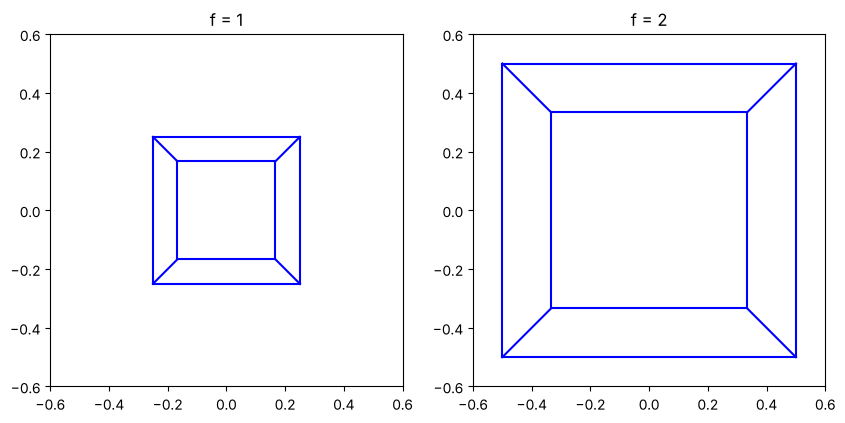

In [ ]:
def project(P, f):
    """Pinhole projection of 3-D points P (n x 3) with focal length f."""
    X, Y, Z = P[:, 0], P[:, 1], P[:, 2]
    return np.stack([f * X / Z, f * Y / Z], axis=1)

cube = np.array([[x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (4, 6)], float)
edges = [(i, j) for i in range(8) for j in range(i + 1, 8)
         if np.sum(cube[i] != cube[j]) == 1]  

def draw(P2, ax, title):
    for i, j in edges:
        ax.plot(*P2[[i, j]].T, "b-")
    ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.6, 0.6)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, f in zip(axes, [1, 2]):
    draw(project(cube, f), ax, f"f = {f}")
plt.show()

**A.2 — parallel lines meet**

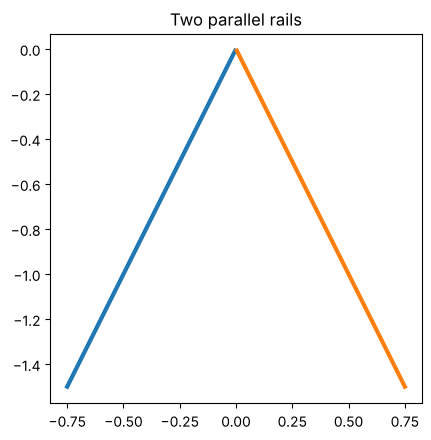

Far end of the rails: [-0.00375 -0.0075 ] [ 0.00375 -0.0075 ]


In [3]:
Z = np.linspace(1, 200, 100)
left  = np.stack([np.full_like(Z, -0.75), np.full_like(Z, -1.5), Z], axis=1)
right = np.stack([np.full_like(Z,  0.75), np.full_like(Z, -1.5), Z], axis=1)
for rail in (left, right):
    p = project(rail, 1.0)
    plt.plot(p[:, 0], p[:, 1], lw=3)
plt.gca().set_aspect("equal"); plt.title("Two parallel rails")
plt.show()
print("Far end of the rails:", project(left, 1)[-1], project(right, 1)[-1])

### Task 1: Perspective

Height on the sensor: 9.00 mm  ->  2250 pixels tall
Y =  -1.5: left rail at Z=1e7 -> [-7.5e-08 -1.5e-07],  right rail -> [ 7.5e-08 -1.5e-07]
Y =  -0.5: left rail at Z=1e7 -> [-7.5e-08 -5.0e-08],  right rail -> [ 7.5e-08 -5.0e-08]
Y =   3.0: left rail at Z=1e7 -> [-7.5e-08  3.0e-07],  right rail -> [7.5e-08 3.0e-07]


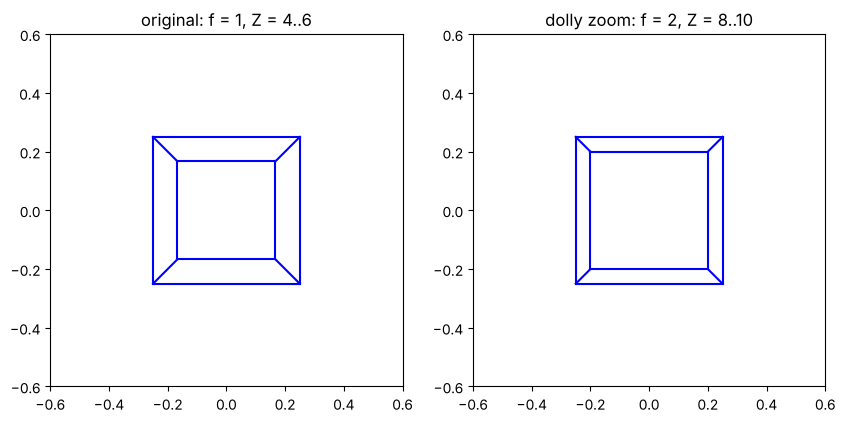

original: front face width = 0.500,  back face width = 0.333,  ratio back/front = 0.667
dolly   : front face width = 0.500,  back face width = 0.400,  ratio back/front = 0.800


In [ ]:
H, Zdist, f_mm, pix_um = 1.8, 10.0, 50.0, 4.0
h_mm = f_mm * H / Zdist                
h_pix = h_mm * 1000 / pix_um           
print(f"Height on the sensor: {h_mm:.2f} mm  ->  {h_pix:.0f} pixels tall")

for Yrail in (-1.5, -0.5, 3.0):
    Zbig = np.array([1e3, 1e5, 1e7])
    L = np.stack([np.full_like(Zbig, -0.75), np.full_like(Zbig, Yrail), Zbig], axis=1)
    R = np.stack([np.full_like(Zbig,  0.75), np.full_like(Zbig, Yrail), Zbig], axis=1)
    print(f"Y = {Yrail:5.1f}: left rail at Z=1e7 -> {project(L,1)[-1]},  right rail -> {project(R,1)[-1]}")

cube2 = cube.copy(); cube2[:, 2] += 4         
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw(project(cube,  1), axes[0], "original: f = 1, Z = 4..6")
draw(project(cube2, 2), axes[1], "dolly zoom: f = 2, Z = 8..10")
plt.show()
for name, c, ff in [("original", cube, 1), ("dolly   ", cube2, 2)]:
    p = project(c, ff)
    front = p[c[:, 2] == c[:, 2].min()]; back = p[c[:, 2] == c[:, 2].max()]
    print(f"{name}: front face width = {np.ptp(front[:,0]):.3f},  back face width = {np.ptp(back[:,0]):.3f},"
          f"  ratio back/front = {np.ptp(back[:,0])/np.ptp(front[:,0]):.3f}")

**Answers — Task 1**

**1.** Similar triangles: $y = f\,Y/Z = 50\text{ mm}\times 1.8/10 = \mathbf{9\ mm}$ on the sensor. With 4 µm pixels: $9\text{ mm} = 9000\ \mu m$, and $9000/4 = \mathbf{2250}$ pixels tall.

**2.** As $Z\to\infty$, both $X/Z \to 0$ and $Y/Z \to 0$, so both rails converge to the image point $(0,0)$ (the principal point, i.e. the image centre / horizon). This is the **vanishing point**. Changing the rail height $Y$ (−1.5, −0.5, 3.0) does **not** move it: the printed far-end points all shrink towards $(0,0)$ (the $Y$ only changes how fast, e.g. $-1.5\times10^{-7}$ vs $3\times10^{-7}$ at $Z=10^7$). The vanishing point depends only on the *direction* of the lines (here: along $Z$), not on where the lines are.

**3.** Dolly zoom (cube moved from $Z=4..6$ to $Z=8..10$, $f$ from 1 to 2). The **front face keeps its size** (width 0.500 in both) because $f/Z = 1/4 = 2/8$. The **back face gets bigger** (width 0.333 → 0.400, ratio back/front 0.667 → 0.800) because $f/Z$ goes from $1/6$ to $2/10$. The extra distance $\Delta Z = 2$ is a smaller fraction of the total distance, so the depth differences matter less: perspective becomes weaker and the cube looks *flatter* (more like an orthographic view). This is the classic "Vertigo" effect used in film.

## Part B — The Sensor: From Light to RAW

**B.1 — a simulated camera (do not change)**

In [ ]:
def add_card(img, value=200, size=48):
    """Put a neutral gray card in the top-left corner of the scene."""
    out = img.copy()
    out[8:8 + size, 8:8 + size] = value
    return out

CARD = (slice(8, 56), slice(8, 56))         
CARD_LINEAR = (200 / 255) ** 2.2         
def capture(scene_lin, light, exposure=1.0, iso=100, bits=10, seed=0):
    """Simulate a sensor. Returns a 10-bit RGGB Bayer RAW image (uint16)."""
    rng = np.random.default_rng(seed)
    rad = scene_lin * light * exposure          
    h, w, _ = rad.shape
    bayer = np.zeros((h, w))
    bayer[0::2, 0::2] = rad[0::2, 0::2, 0]       
    bayer[0::2, 1::2] = rad[0::2, 1::2, 1]     
    bayer[1::2, 0::2] = rad[1::2, 0::2, 1]      
    bayer[1::2, 1::2] = rad[1::2, 1::2, 2]      
    e = bayer * 1000                             
    e = rng.normal(e, np.sqrt(np.maximum(e, 0)) + 2)  
    signal = e / 1000 * (iso / 100)             
    full = 2 ** bits - 1
    return np.clip(np.round(signal * full), 0, full).astype(np.uint16)   

**B.2 — take a picture**

uint16 (512, 512) 0 1023


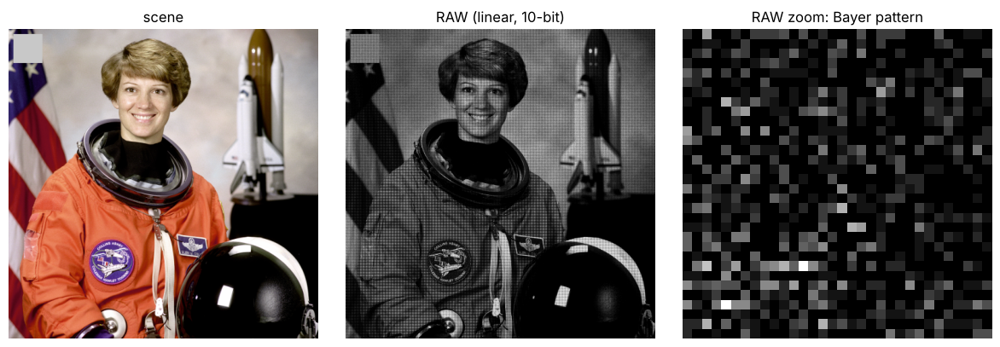

In [ ]:
scene = add_card(data.astronaut())               
scene_lin = (scene / 255.0) ** 2.2                 
tungsten = np.array([1.0, 0.8, 0.5])              

raw = capture(scene_lin, tungsten)
print(raw.dtype, raw.shape, raw.min(), raw.max())
show_row([scene, raw / 1023, raw[200:232, 200:232] / 1023],
         ["scene", "RAW (linear, 10-bit)", "RAW zoom: Bayer pattern"])

### Task 2: ISO and noise

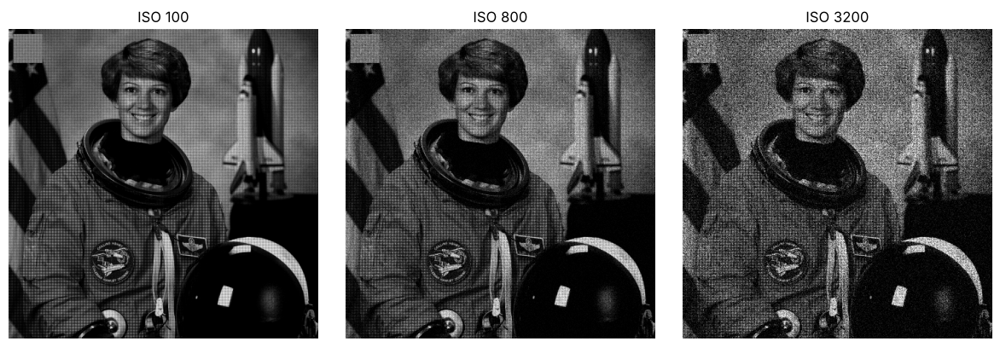

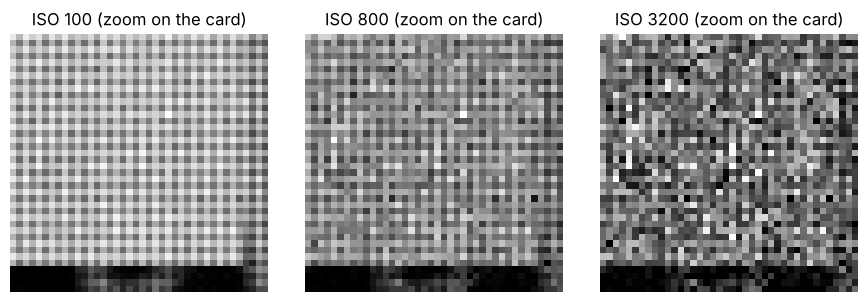

Noise on the gray card (a flat area), measured on the green pixels of the Bayer mosaic:
  ISO   100: mean =  479.1   std =  23.5   SNR = mean/std =  20.4
  ISO   800: mean =  478.2   std =  76.8   SNR = mean/std =   6.2
  ISO  3200: mean =  476.9   std = 182.1   SNR = mean/std =   2.6

Image size: 512 x 512 = 262,144 pixels
RAW 10-bit : 327,680 bytes = 320 KB   (stored in uint16: 524,288 bytes)
RGB 8-bit  : 786,432 bytes = 768 KB
RGB / RAW(packed) = 2.40x


In [ ]:
raws = {}
for iso in (100, 800, 3200):
    exposure = 100 / iso
    raws[iso] = capture(scene_lin, tungsten, exposure=exposure, iso=iso, seed=0)
show_row([r / 1023 for r in raws.values()],
         [f"ISO {iso}" for iso in raws])

show_row([r[20:60, 20:60] / 1023 for r in raws.values()],
         [f"ISO {iso} (zoom on the card)" for iso in raws], size=3)

print("Noise on the gray card (a flat area), measured on the green pixels of the Bayer mosaic:")
for iso, r in raws.items():
    g = r[CARD][0::2, 1::2].astype(float)     
    print(f"  ISO {iso:5d}: mean = {g.mean():6.1f}   std = {g.std():5.1f}   SNR = mean/std = {g.mean()/g.std():5.1f}")

h, w = raw.shape
raw_bytes_packed = h * w * 10 / 8             
rgb_bytes = h * w * 3                        
print(f"\nImage size: {w} x {h} = {h*w:,} pixels")
print(f"RAW 10-bit : {raw_bytes_packed:,.0f} bytes = {raw_bytes_packed/1024:.0f} KB   (stored in uint16: {raw.nbytes:,} bytes)")
print(f"RGB 8-bit  : {rgb_bytes:,} bytes = {rgb_bytes/1024:.0f} KB")
print(f"RGB / RAW(packed) = {rgb_bytes/raw_bytes_packed:.2f}x")

**Answers — Task 2**

**1.** The **ISO 3200** image is the noisiest, ISO 100 the cleanest. The measured noise on the flat gray card (same mean ≈ 478 for all three, so the brightness is equal) is:

| ISO | mean | noise (std) | SNR |
|---|---|---|---|
| 100 | 479 | 23.5 | 20.4 |
| 800 | 478 | 76.8 | 6.2 |
| 3200 | 477 | 182.1 | 2.6 |

Why the same brightness still gives more noise: to keep $\text{exposure}\times\text{ISO}/100 = 1$ we must *reduce the exposure* when we raise the ISO (ISO 3200 → exposure 1/32). So the sensor collects 32× **fewer photons/electrons**. Shot noise is $\sqrt{N}$, so the SNR is $\sqrt{N}$: ~1000 e⁻ gives SNR ≈ 31.6, but ~31 e⁻ gives SNR ≈ 5.6. The analog gain then multiplies signal **and** noise by the same factor 32, so it brings back the brightness but not the SNR. Gain cannot create information the sensor never collected. (The measured SNR is a bit lower than $\sqrt N$ because the card is not at full well, and there is an extra read noise of 2 e⁻ that the gain also amplifies.)

**2.** One RAW value per pixel × 10 bits: $512\times512\times10/8 = \mathbf{327{,}680}$ bytes $= 320$ KB (stored as `uint16` in Python it is 524,288 bytes, because 10 bits do not fit a byte and NumPy uses 16). An 8-bit RGB image has 3 bytes per pixel: $512\times512\times3 = \mathbf{786{,}432}$ bytes $= 768$ KB. So the RAW file is **2.4× smaller** than the RGB image (it stores only one colour per pixel, even though it uses 10 instead of 8 bits), but RAW is still much bigger than a JPEG.

## Part C — Developing the RAW

**C.1 — demosaic, white balance, gamma**

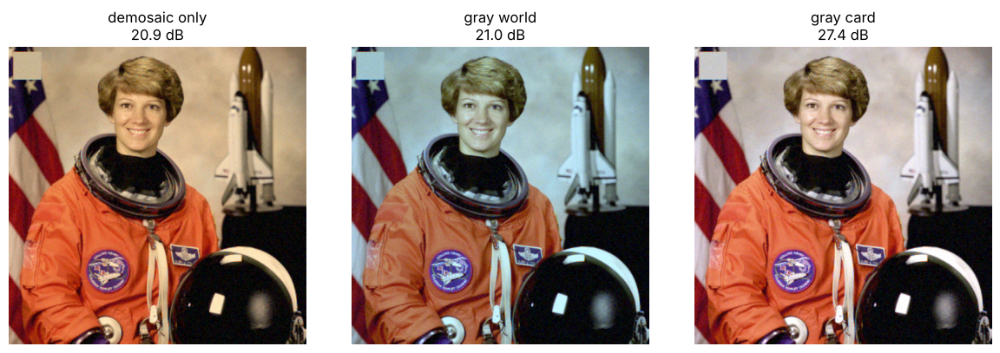

In [ ]:
def demosaic(raw, bits=10):
    """RGGB Bayer -> RGB float in [0, 1] (still linear)."""
    rgb = cv2.cvtColor(raw, cv2.COLOR_BayerBG2RGB)  
    return rgb.astype(np.float64) / (2 ** bits - 1)

def gray_world(rgb):
    means = rgb.reshape(-1, 3).mean(axis=0)
    return np.clip(rgb * means.mean() / means, 0, 1)

def gray_card(rgb):
    card = rgb[CARD].reshape(-1, 3).mean(axis=0)
    return np.clip(rgb * CARD_LINEAR / card, 0, 1)

def to_srgb(rgb):
    """Linear [0, 1] -> display gamma -> uint8."""
    return np.round(255 * np.clip(rgb, 0, 1) ** (1 / 2.2)).astype(np.uint8)

lin = demosaic(raw)
stages = {"demosaic only": to_srgb(lin),
          "gray world":    to_srgb(gray_world(lin)),
          "gray card":     to_srgb(gray_card(lin))}
show_row(list(stages.values()),
         [f"{k}\n{psnr(scene, v):.1f} dB" for k, v in stages.items()])

**C.2 — JPEG: quality vs. file size**

In [ ]:
img = stages["gray card"]
bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)       
for q in [95, 75, 30, 5]:
    ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
    back = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    print(f"quality {q:3d}: {len(buf)/1024:6.1f} KB   PSNR {psnr(img, back):.1f} dB")
print(f"uncompressed: {img.nbytes/1024:.1f} KB")

quality  95:  123.3 KB   PSNR 31.8 dB
quality  75:   43.4 KB   PSNR 29.8 dB
quality  30:   19.9 KB   PSNR 28.5 dB
quality   5:    7.7 KB   PSNR 24.1 dB
uncompressed: 768.0 KB


### Task 3: Develop the astronaut

Mean of each channel of scene_lin (R, G, B): [0.395 0.247 0.223]
Gray-world assumption says they should all be equal. Ratio to green: [1.6 1.  0.9]
Gray-world gains it will apply to the *true* scene: [0.73 1.17 1.29]
Gains the gray card finds (true light is [1.  0.8 0.5] ): [1.01 1.26 2.03]

PSNR with gamma    : 27.4 dB
PSNR without gamma : 14.3 dB


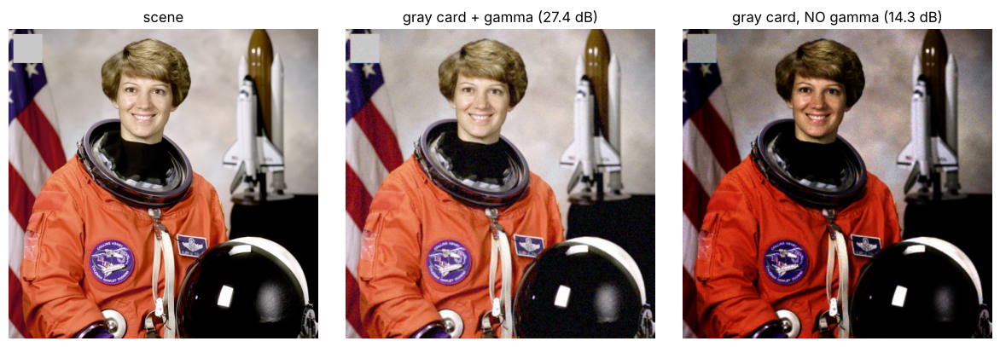


 quality |  size (KB) | PSNR (dB) |  smaller than raw by
----------------------------------------------------------
      95 |      123.3 |      31.8 |                 6.2x
      75 |       43.4 |      29.8 |                17.7x
      30 |       19.9 |      28.5 |                38.6x
       5 |        7.7 |      24.1 |                99.3x
    none |      768.0 |       inf |                 1.0x


In [ ]:
means_scene = scene_lin.reshape(-1, 3).mean(axis=0)
print("Mean of each channel of scene_lin (R, G, B):", np.round(means_scene, 3))
print("Gray-world assumption says they should all be equal. Ratio to green:", np.round(means_scene / means_scene[1], 2))
print("Gray-world gains it will apply to the *true* scene:", np.round(means_scene.mean() / means_scene, 2))
print("Gains the gray card finds (true light is", tungsten, "):", np.round(CARD_LINEAR / lin[CARD].reshape(-1, 3).mean(axis=0), 2))

no_gamma = np.round(255 * gray_card(lin)).astype(np.uint8)
print(f"\nPSNR with gamma    : {psnr(scene, stages['gray card']):.1f} dB")
print(f"PSNR without gamma : {psnr(scene, no_gamma):.1f} dB")
show_row([scene, stages["gray card"], no_gamma],
         ["scene", f"gray card + gamma ({psnr(scene, stages['gray card']):.1f} dB)",
          f"gray card, NO gamma ({psnr(scene, no_gamma):.1f} dB)"])

rows = []
for q in [95, 75, 30, 5]:
    ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
    back = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    rows.append((q, len(buf) / 1024, psnr(img, back), img.nbytes / len(buf)))
print(f"\n{'quality':>8} | {'size (KB)':>10} | {'PSNR (dB)':>9} | {'smaller than raw by':>20}")
print("-" * 58)
for q, kb, p, ratio in rows:
    print(f"{q:>8} | {kb:>10.1f} | {p:>9.1f} | {ratio:>19.1f}x")
print(f"{'none':>8} | {img.nbytes/1024:>10.1f} | {'inf':>9} | {1.0:>19.1f}x")

**Answers — Task 3**

**1.** Means of `scene_lin` (R, G, B) = **(0.395, 0.247, 0.223)**. Gray world assumes these are equal, but the astronaut photo is *not* gray on average: it has lots of warm, reddish content (skin, orange tones) so R is ~1.6× G. Gray world therefore thinks "the light is too red" and **removes the red that really belongs to the scene** (gains 0.73, 1.17, 1.29), whereas the real light correction needed is about (1.0, 1.26, 2.03), found by the gray card. The result barely improves: 20.9 dB (demosaic only) → 21.0 dB (gray world). The gray card measures the *light*, not the scene, so it gives the right gains and reaches **27.4 dB**.

**2.** Without the gamma step (`np.round(255 * gray_card(lin))`) the PSNR drops from **27.4 dB to 14.3 dB** and the image looks **much too dark and contrasty**. The linear values are stored directly, but the screen applies its own gamma ($\approx v^{2.2}$) when displaying, so mid-tones are pushed down (a linear 0.5 is shown as ≈0.22) and all the dark detail is crushed. Gamma encoding is what makes the 8-bit values match what the screen expects (and what the eye notices).

**3.** Table (image 512×512, uncompressed 8-bit RGB = 768.0 KB):

| JPEG quality | file size | PSNR | smaller than uncompressed |
|---|---|---|---|
| 95 | 123.3 KB | 31.8 dB | 6.2× |
| 75 | 43.4 KB | 29.8 dB | 17.7× |
| 30 | 19.9 KB | 28.5 dB | 38.6× |
| 5 | 7.7 KB | 24.1 dB | 99.3× |
| none | 768.0 KB | ∞ | 1× |

For a photo-sharing app I would choose **quality 75**: PSNR ≈ 29.8 dB is close to the "hard to see the difference" level (30 dB), and the file is **about 17.7× smaller** (43.4 KB vs 768 KB). Quality 95 costs almost 3× more bytes for very little visible gain, and quality 5 drops to 24 dB (visible blocking).

## Part D — Color Spaces Beyond RGB

**D.1 — the eye cares more about brightness than color**

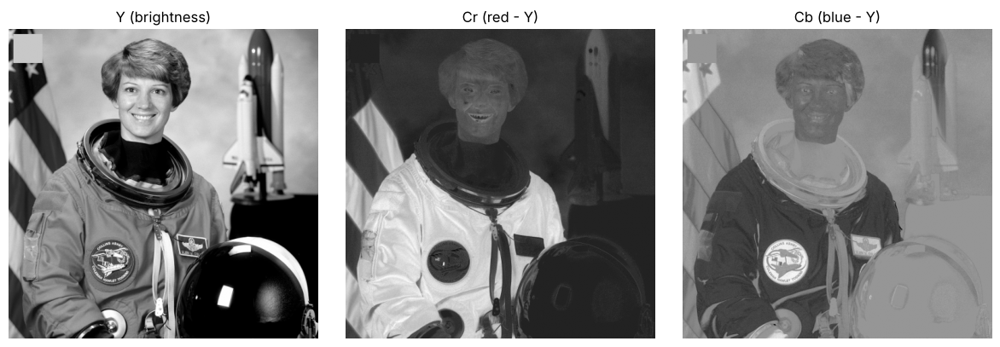

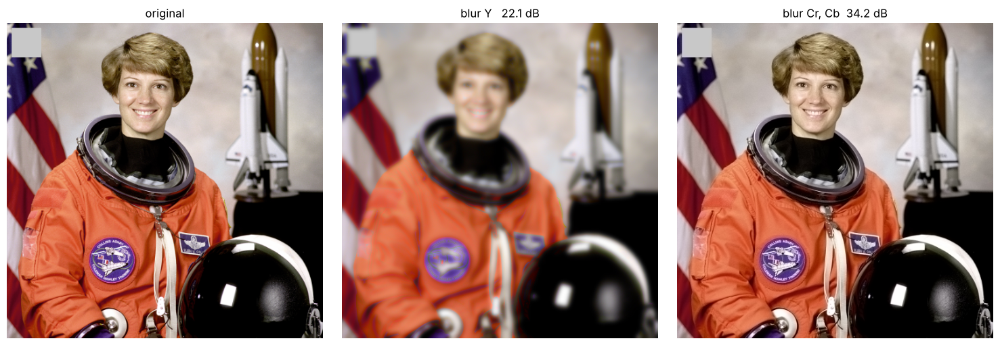

In [11]:
ycc = cv2.cvtColor(scene, cv2.COLOR_RGB2YCrCb)
Y, Cr, Cb = cv2.split(ycc)
show_row([Y, Cr, Cb], ["Y (brightness)", "Cr (red - Y)", "Cb (blue - Y)"])

def blur_channels(ycc, channels, k=21):
    out = ycc.copy()
    for c in channels:
        out[:, :, c] = cv2.GaussianBlur(out[:, :, c], (k, k), 0)
    return cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB)

blur_Y    = blur_channels(ycc, [0])
blur_CrCb = blur_channels(ycc, [1, 2])
show_row([scene, blur_Y, blur_CrCb],
         ["original", f"blur Y   {psnr(scene, blur_Y):.1f} dB",
          f"blur Cr, Cb  {psnr(scene, blur_CrCb):.1f} dB"], size=5)

### Task 4: Chroma subsampling

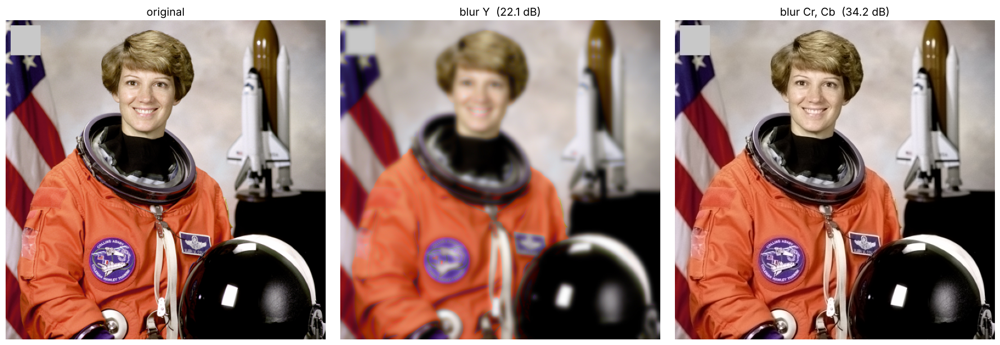

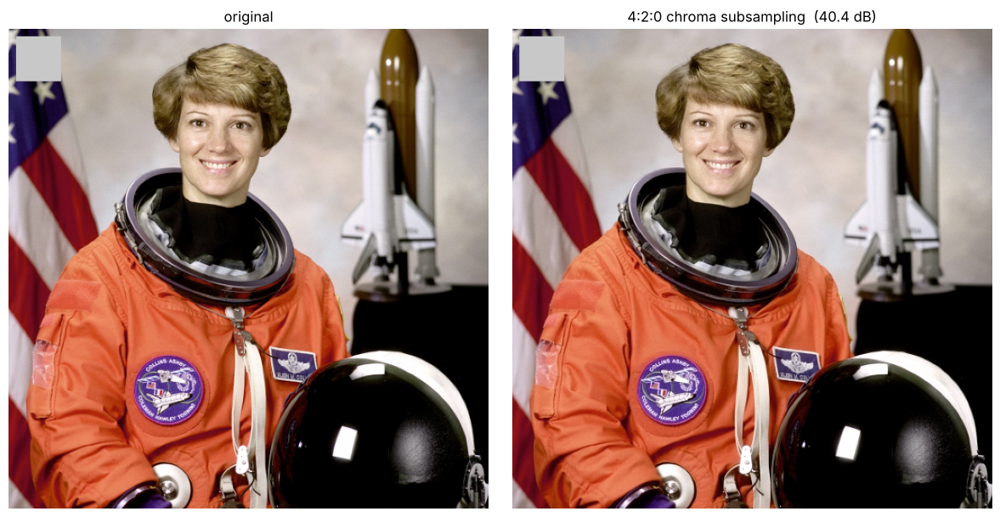

PSNR of 4:2:0 vs original: 40.4 dB
PSNR when blurring Cr, Cb with a 21x21 Gaussian: 34.2 dB
values kept: 393,216 of 786,432  =  50%


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, im, t in zip(axes, [scene, blur_Y, blur_CrCb],
                     ["original", f"blur Y  ({psnr(scene, blur_Y):.1f} dB)", f"blur Cr, Cb  ({psnr(scene, blur_CrCb):.1f} dB)"]):
    ax.imshow(im); ax.set_title(t, fontsize=14); ax.axis("off")
plt.tight_layout(); plt.show()

def subsample_420(rgb):
    ycc = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
    h, w = ycc.shape[:2]
    out = ycc.copy()
    for c in (1, 2):
        small = cv2.resize(ycc[:, :, c], (w // 2, h // 2), interpolation=cv2.INTER_AREA)  
        out[:, :, c] = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)         
    return cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB)

sub = subsample_420(scene)
show_row([scene, sub], ["original", f"4:2:0 chroma subsampling  ({psnr(scene, sub):.1f} dB)"], size=6)
print(f"PSNR of 4:2:0 vs original: {psnr(scene, sub):.1f} dB")
print(f"PSNR when blurring Cr, Cb with a 21x21 Gaussian: {psnr(scene, blur_CrCb):.1f} dB")
H_, W_ = scene.shape[:2]
full_vals = H_ * W_ * 3
kept_vals = H_ * W_ + 2 * (H_ // 2) * (W_ // 2)
print(f"values kept: {kept_vals:,} of {full_vals:,}  =  {kept_vals/full_vals:.0%}")

**Answers — Task 4**

**1.** The image where **Cr and Cb are blurred** looks almost identical to the original at full size, while the image where **Y is blurred** is clearly soft (lost fine detail, edges and texture). PSNR **agrees** with the eye: blur Cr,Cb = **34.2 dB** vs blur Y = **22.1 dB**. This is because the eye sees fine detail in brightness but only coarse detail in colour.

**2.** With 4:2:0 subsampling (Cr, Cb shrunk to half size in both directions with `INTER_AREA`, then enlarged back) the PSNR is **40.4 dB** (even higher than the 21×21 chroma blur, 34.2 dB, since the loss is much smaller): practically invisible. The data kept: for every 2×2 block, 4 Y + 1 Cr + 1 Cb = 6 numbers instead of 12, i.e. **50 %** of the original data (393,216 of 786,432 values).

## Mini-Challenge: Develop the RAW

**MC — the RAW file (do not change this cell)**

Straight from the sensor: 12.4 dB


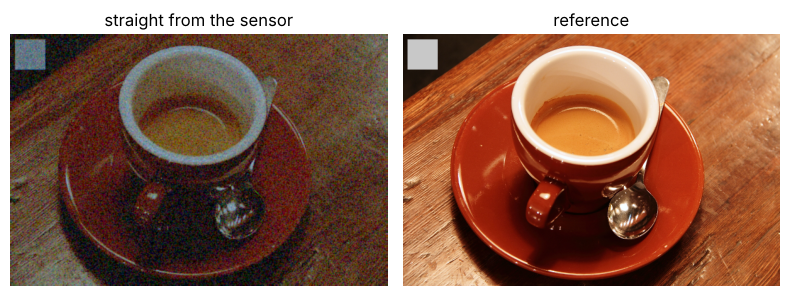

In [ ]:
coffee = add_card(data.coffee())                 
shade = np.array([0.55, 0.8, 1.0])               
raw_mc = capture((coffee / 255.0) ** 2.2, shade, exposure=0.05, iso=800, seed=4)

straight = to_srgb(demosaic(raw_mc))
print(f"Straight from the sensor: {psnr(coffee, straight):.1f} dB")   
show_row([straight, coffee], ["straight from the sensor", "reference"])

### Task 5: `develop(raw)`

12.43 dB   0. straight from the sensor (demosaic + gamma)
17.87 dB   1. + gray-card white balance & exposure (linear)
22.74 dB   2. + denoise after gamma (bilateral Y, blur Cr/Cb)
21.19 dB      variant: denoise BEFORE gamma

Goal >= 21 dB: PASS    Bonus >= 22 dB: PASS


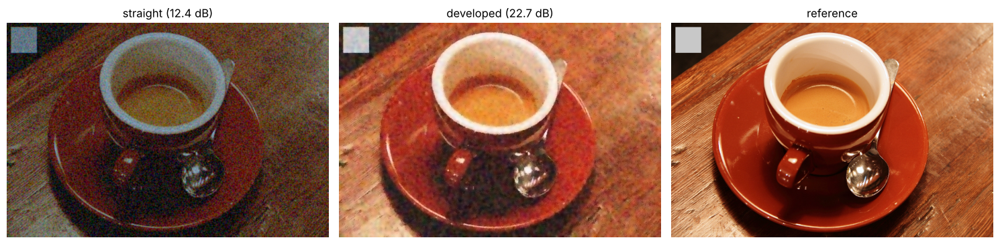

In [ ]:
def denoise_ycc(img8, k_chroma=21, y_d=9, y_sigma_color=40, y_sigma_space=5):
    """Denoise an 8-bit RGB image in YCrCb.
    Y (brightness, the eye is sensitive to it): edge-preserving bilateral filter.
    Cr, Cb (color, the eye barely sees blur): strong Gaussian blur."""
    ycc = cv2.cvtColor(img8, cv2.COLOR_RGB2YCrCb)
    out = ycc.copy()
    out[:, :, 0]  = cv2.bilateralFilter(ycc[:, :, 0], y_d, y_sigma_color, y_sigma_space)
    out[:, :, 1:] = cv2.GaussianBlur(ycc[:, :, 1:], (k_chroma, k_chroma), 0)
    return cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB)

def develop(raw, denoise_before_gamma=False, verbose=False):
    """RAW (10-bit Bayer) -> 8-bit RGB. Order: demosaic -> white balance (gray card) -> denoise -> gamma."""
    lin = demosaic(raw)                        
    lin = gray_card(lin)                  
    if denoise_before_gamma:                 
        lin8 = np.round(255 * lin).astype(np.uint8)
        lin = denoise_ycc(lin8).astype(np.float64) / 255
    out = to_srgb(lin)                      
    if not denoise_before_gamma:
        out = denoise_ycc(out)             
    return out

lin = demosaic(raw_mc)
steps = [("0. straight from the sensor (demosaic + gamma)", to_srgb(lin)),
         ("1. + gray-card white balance & exposure (linear)", to_srgb(gray_card(lin))),
         ("2. + denoise after gamma (bilateral Y, blur Cr/Cb)", develop(raw_mc)),
         ("   variant: denoise BEFORE gamma",                   develop(raw_mc, denoise_before_gamma=True))]
for name, im in steps:
    print(f"{psnr(coffee, im):5.2f} dB   {name}")

developed = develop(raw_mc)
print(f"\nGoal >= 21 dB: {'PASS' if psnr(coffee, developed) >= 21 else 'FAIL'}    Bonus >= 22 dB: {'PASS' if psnr(coffee, developed) >= 22 else 'FAIL'}")
show_row([straight, developed, coffee],
         [f"straight ({psnr(coffee, straight):.1f} dB)", f"developed ({psnr(coffee, developed):.1f} dB)", "reference"], size=5)

**Steps in order (with PSNR after each step):**

| # | Step | PSNR vs. `coffee` |
|---|---|---|
| 0 | straight from the sensor (demosaic + gamma) | 12.43 dB |
| 1 | **Demosaic** (`cv2.cvtColor`, linear) | — (intermediate, linear data) |
| 2 | **White balance + exposure with the gray card** (linear light), then gamma | 17.87 dB |
| 3 | **Gamma** (`v ** (1/2.2)`) — last colour/brightness step | (included in step 2's number) |
| 4 | **Denoise** in YCrCb: bilateral filter on Y, strong 21×21 Gaussian blur on Cr and Cb | **22.74 dB** |
| – | variant: denoise *before* gamma | 21.19 dB |

Goal (≥ 21 dB) ✅ and bonus (≥ 22 dB) ✅ with **22.74 dB**.

**Why this order works**

1. **Demosaic first**: white balance and denoising work on full RGB pixels, but the RAW has only one colour per pixel.
2. **White balance before gamma**: the gains $g_c = \text{target}/\text{measured}$ are only valid in **linear** light (see "Gamma comes last"). Using the **gray card** is the right choice here: the scene is dominated by brown/orange coffee and a warm table, so gray world would fail, and the card also fixes the **exposure** (the photo was underexposed, `exposure=0.05`): the card's known value $0.586$ scales the gains so brightness also becomes correct. This gives the big jump 12.4 → 17.9 dB.
3. **Gamma after white balance**: it only re-encodes brightness for the screen.
4. **Denoise**: the ISO 800 + underexposure leaves strong noise. I tried it both before and after gamma, as the hint says, and kept the higher PSNR (after gamma: 22.74 dB vs 21.19 dB before). Following Part D, I smooth **Cr and Cb much more than Y** (the eye barely sees blur in colour), and only use an edge-preserving bilateral filter on Y so the details of the cup are not lost. This adds +4.9 dB.